In [1]:
# !pip install rasterio planetary-computer pystac-client scipy matplotlib numpy pandas

In [1]:
import os
import numpy as np
import rasterio
import planetary_computer
import pystac_client
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from rasterio.warp import reproject, Resampling
from scipy.ndimage import binary_dilation

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
#Connect to Sentinel-2 imagery

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace
)

print("Connected to Planetary Computer.")

Connected to Planetary Computer.


In [3]:
SCENE_IDS = [
    "S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244"
    # "S2B_MSIL2A_20251010T171139_R112_T15TVG_20251010T220405",
    # "S2C_MSIL2A_20251002T170141_R069_T15TVG_20251002T222514"
]

items = list(
    catalog.search(
        collections=["sentinel-2-l2a"],
        ids=SCENE_IDS
    ).items()
)

print("Scenes retrieved:", len(items))

for item in items:
    print(item.id, item.datetime)

Scenes retrieved: 1
S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244 2025-09-27 16:59:59.024000+00:00


In [4]:
#preprocessing output order

PROJECT_DIR = Path(r"C:\Users\ABCOM\ftw-baselines")

OUTPUT_DIR = PROJECT_DIR / "satellite_preprocessing"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder:", OUTPUT_DIR)

Output folder: C:\Users\ABCOM\ftw-baselines\satellite_preprocessing


In [5]:
#inspecting available satellite bands

for item in items:

    print("\nScene:", item.id)

    for band in ["B02", "B03", "B04", "B08", "SCL"]:
        if band in item.assets:
            print(band, "Available")
        else:
            print(band, "Missing")


Scene: S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244
B02 Available
B03 Available
B04 Available
B08 Available
SCL Available


In [6]:
#Apply cloud and shadow masking and align the bands

def read_band_on_reference(item, band_name, reference):

    asset = item.assets[band_name]

    with rasterio.open(asset.href) as src:

        destination = np.zeros(
            (reference.height, reference.width),
            dtype=np.uint16
        )

        reproject(
            source=rasterio.band(src, 1),
            destination=destination,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=reference.transform,
            dst_crs=reference.crs,
            resampling=Resampling.nearest,
            src_nodata=src.nodata,
            dst_nodata=0
        )

    return destination


def preprocess_scene(item):

    print("\nProcessing:", item.id)

    # B02 provides the reference 10 m grid
    b02_href = item.assets["B02"].href

    with rasterio.open(b02_href) as reference:

        profile = reference.profile.copy()

        bands = {}

        # Read and align required bands
        for band in ["B02", "B03", "B04", "B08", "SCL"]:

            bands[band] = read_band_on_reference(
                item,
                band,
                reference
            )

    # Identify invalid SCL classes
    invalid_classes = [0, 1, 3, 7, 8, 9, 10, 11]

    invalid_mask = np.isin(
        bands["SCL"],
        invalid_classes
    )

    # Also exclude pixels with missing spectral data
    invalid_mask |= (
        (bands["B02"] == 0) |
        (bands["B03"] == 0) |
        (bands["B04"] == 0) |
        (bands["B08"] == 0)
    )

    # Expand cloud/shadow mask by approximately 20 m
    invalid_mask = binary_dilation(
        invalid_mask,
        iterations=2
    )

    valid_mask = ~invalid_mask

    # Prepare four-band output
    output_bands = []

    for band in ["B02", "B03", "B04", "B08"]:

        data = bands[band].copy()

        data[~valid_mask] = 0

        output_bands.append(data)

    output_stack = np.stack(output_bands)

    # Save processed image
    output_path = OUTPUT_DIR / f"{item.id}_preprocessed.tif"

    profile.update(
        driver="GTiff",
        count=4,
        dtype="uint16",
        nodata=0,
        compress="deflate"
    )

    with rasterio.open(output_path, "w", **profile) as dst:

        dst.write(output_stack)

        dst.write_mask(
            (valid_mask.astype("uint8") * 255)
        )

        dst.set_band_description(1, "B02_Blue")
        dst.set_band_description(2, "B03_Green")
        dst.set_band_description(3, "B04_Red")
        dst.set_band_description(4, "B08_NIR")

    # Calculate image quality statistics
    total_pixels = valid_mask.size

    invalid_percent = (
        np.count_nonzero(~valid_mask) /
        total_pixels
    ) * 100

    valid_percent = (
        np.count_nonzero(valid_mask) /
        total_pixels
    ) * 100

    print("Output:", output_path)
    print("Valid pixels:", round(valid_percent, 2), "%")
    print("Masked pixels:", round(invalid_percent, 2), "%")

    return {
        "scene_id": item.id,
        "output": str(output_path),
        "valid_percent": valid_percent,
        "masked_percent": invalid_percent
    }

In [7]:
# process the selected scenes

results = []

for item in items:

    result = preprocess_scene(item)

    results.append(result)

quality_df = pd.DataFrame(results)

display(quality_df)


Processing: S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244
Output: C:\Users\ABCOM\ftw-baselines\satellite_preprocessing\S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244_preprocessed.tif
Valid pixels: 100.0 %
Masked pixels: 0.0 %


,scene_id,output,valid_percent,masked_percent
0,S2B_MSIL2A_20250927T165959_R069_T15TVG_2025092...,C:\Users\ABCOM\ftw-baselines\satellite_preproc...,99.997791,0.002209


In [8]:
from pathlib import Path

image_path = Path(
    r"C:\Users\ABCOM\ftw-baselines\satellite_preprocessing\S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244_preprocessed.tif"
)

print("Image exists:", image_path.exists())
print("Image path:", image_path)

Image exists: True
Image path: C:\Users\ABCOM\ftw-baselines\satellite_preprocessing\S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244_preprocessed.tif


In [9]:
import rasterio

with rasterio.open(image_path) as src:

    print("Number of bands:", src.count)
    print("Image dimensions:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Resolution:", src.res)
    print("Data types:", src.dtypes)
    print("Band descriptions:", src.descriptions)

    for i in range(1, src.count + 1):
        print(
            f"Band {i}:",
            "Description =", src.descriptions[i - 1],
            "Dtype =", src.dtypes[i - 1]
        )

Number of bands: 4
Image dimensions: 10980 x 10980
CRS: EPSG:32615
Bounds: BoundingBox(left=399960.0, bottom=4590240.0, right=509760.0, top=4700040.0)
Resolution: (10.0, 10.0)
Data types: ('uint16', 'uint16', 'uint16', 'uint16')
Band descriptions: ('B02_Blue', 'B03_Green', 'B04_Red', 'B08_NIR')
Band 1: Description = B02_Blue Dtype = uint16
Band 2: Description = B03_Green Dtype = uint16
Band 3: Description = B04_Red Dtype = uint16
Band 4: Description = B08_NIR Dtype = uint16


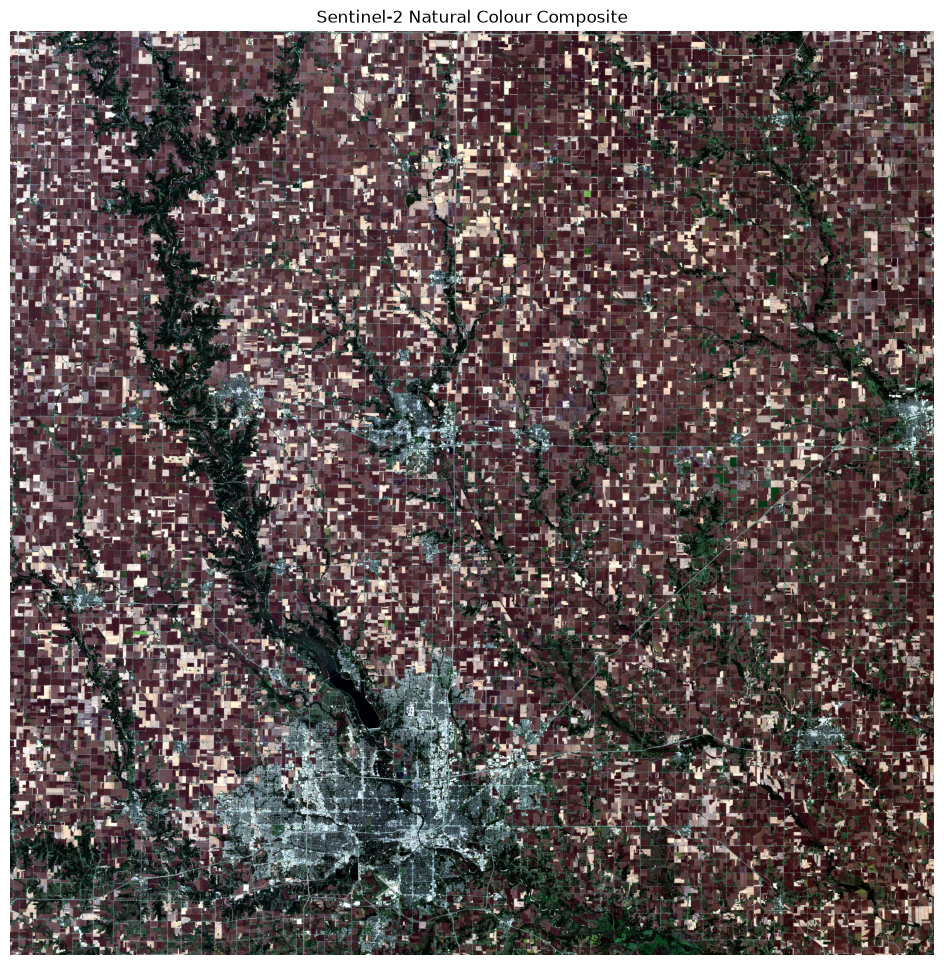

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio

with rasterio.open(image_path) as src:

    blue = src.read(1).astype("float32")
    green = src.read(2).astype("float32")
    red = src.read(3).astype("float32")

def stretch_band(band, lower=2, upper=98):

    valid = np.isfinite(band) & (band > 0)

    low = np.percentile(band[valid], lower)
    high = np.percentile(band[valid], upper)

    stretched = np.clip(
        (band - low) / (high - low),
        0,
        1
    )

    stretched[~valid] = 0

    return stretched

# Contrast stretching
red_stretched = stretch_band(red)
green_stretched = stretch_band(green)
blue_stretched = stretch_band(blue)

# Natural-colour RGB
rgb = np.dstack((
    red_stretched,
    green_stretched,
    blue_stretched
))

# Visualization
plt.figure(figsize=(14, 12))
plt.imshow(rgb)
plt.title("Sentinel-2 Natural Colour Composite")
plt.axis("off")
plt.show()

In [12]:
import rasterio
from rasterio.warp import transform_bounds

with rasterio.open(image_path) as src:

    geographic_bounds = transform_bounds(
        src.crs,
        "EPSG:4326",
        *src.bounds
    )

    west, south, east, north = geographic_bounds

print("Geographic coverage:")
print("West longitude:", west)
print("South latitude:", south)
print("East longitude:", east)
print("North latitude:", north)

Geographic coverage:
West longitude: -94.21648331497752
South latitude: 41.45751520585338
East longitude: -92.8813058263769
North latitude: 42.4526911672117


In [13]:
from pathlib import Path

# Preprocessed Sentinel-2 image
image_path = Path(
    r"C:\Users\ABCOM\ftw-baselines\satellite_preprocessing\S2B_MSIL2A_20250927T165959_R069_T15TVG_20250927T224244_preprocessed.tif"
)

# FTW detected polygons
polygons_path = Path(
    r"C:\Users\ABCOM\ftw-baselines\gps_ftw_output\polygons.parquet"
)

print("Satellite image exists:", image_path.exists())
print("FTW polygons exist:", polygons_path.exists())

Satellite image exists: True
FTW polygons exist: True


In [14]:
import geopandas as gpd

gdf = gpd.read_parquet(polygons_path)

print("Total polygons:", len(gdf))
print("Polygon CRS:", gdf.crs)
print("Geometry type:", gdf.geom_type.value_counts())
print("Columns:", gdf.columns.tolist())

display(gdf.head())

Total polygons: 88
Polygon CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "ProjectedCRS", "name": "WGS 84 / UTM zone 15N", "base_crs": {"type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geod

,metrics:area,id,metrics:perimeter,geometry
0,2500.0,1,240.0,"POLYGON ((445430 4663110, 445430 4663090, 4454..."
1,6000.0,2,460.0,"POLYGON ((442960 4663110, 442960 4663100, 4429..."
2,5900.0,3,400.0,"POLYGON ((445400 4663100, 445400 4663010, 4454..."
3,8800.0,4,700.0,"POLYGON ((441580 4663100, 441580 4663020, 4415..."
4,500.0,5,120.0,"POLYGON ((441650 4662940, 441650 4662920, 4416..."


In [15]:
import numpy as np
import rasterio

with rasterio.open(image_path) as src:

    # Read at reduced resolution
    scale = 4

    height = src.height // scale
    width = src.width // scale

    red = src.read(
        3,
        out_shape=(height, width)
    ).astype("float32")

    green = src.read(
        2,
        out_shape=(height, width)
    ).astype("float32")

    blue = src.read(
        1,
        out_shape=(height, width)
    ).astype("float32")

    image_crs = src.crs
    image_bounds = src.bounds

print("RGB image dimensions:", width, "x", height)
print("Image CRS:", image_crs)

RGB image dimensions: 2745 x 2745
Image CRS: EPSG:32615


In [16]:
def stretch_band(band, lower=2, upper=98):

    valid = np.isfinite(band) & (band > 0)

    low, high = np.percentile(
        band[valid],
        [lower, upper]
    )

    if high <= low:
        raise ValueError("Invalid contrast range")

    stretched = np.clip(
        (band - low) / (high - low),
        0,
        1
    )

    stretched[~valid] = 0

    return stretched


rgb = np.dstack([
    stretch_band(red),
    stretch_band(green),
    stretch_band(blue)
])

print("RGB array shape:", rgb.shape)

RGB array shape: (2745, 2745, 3)


Total FTW polygons: 88
Polygons overlapping satellite image: 88


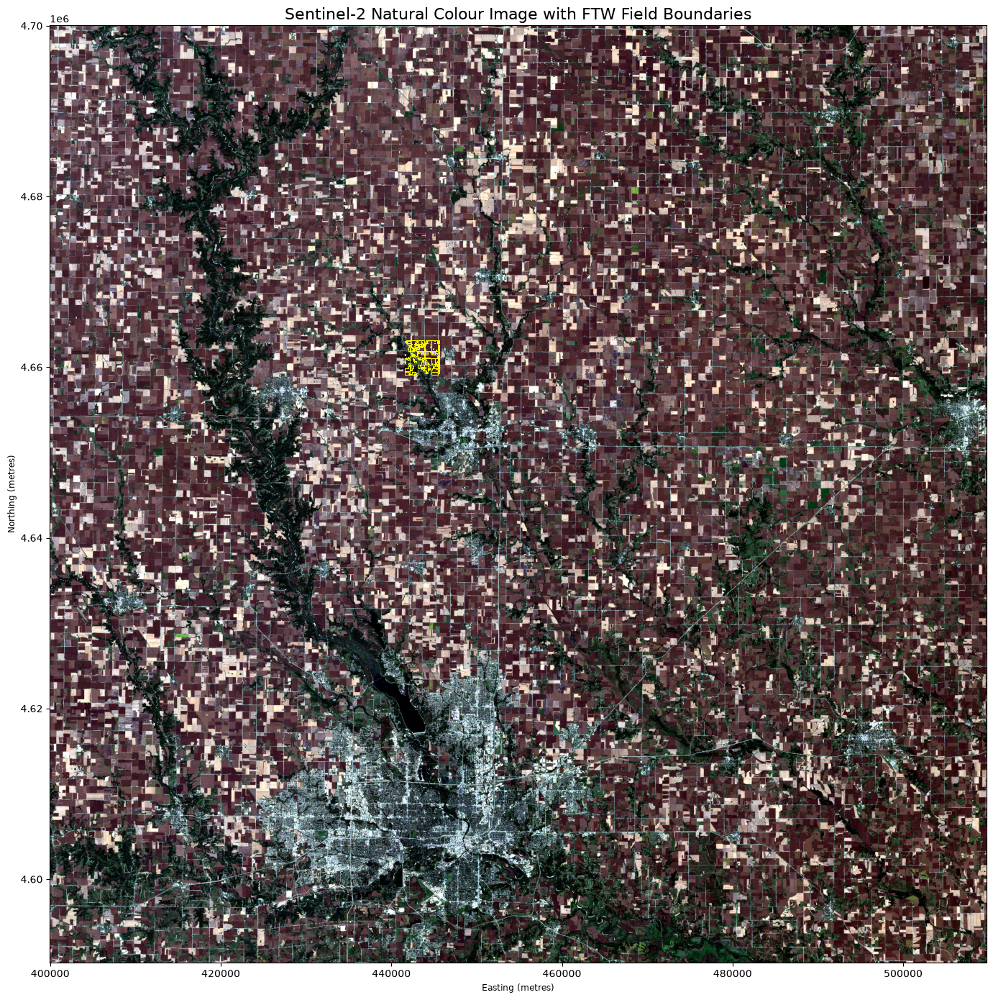

In [17]:
import matplotlib.pyplot as plt
from shapely.geometry import box

# Ensure polygons use the satellite image CRS
if gdf.crs is None:
    raise ValueError("FTW polygons have no CRS. Check their original CRS.")

gdf_image = gdf.to_crs(image_crs)

# Create satellite image boundary
image_box = box(
    image_bounds.left,
    image_bounds.bottom,
    image_bounds.right,
    image_bounds.top
)

# Select polygons that intersect the satellite image
gdf_overlap = gdf_image[
    gdf_image.intersects(image_box)
].copy()

# Clip polygons to image boundary
gdf_overlap.geometry = gdf_overlap.geometry.intersection(image_box)

gdf_overlap = gdf_overlap[
    ~gdf_overlap.geometry.is_empty
]

print("Total FTW polygons:", len(gdf))
print("Polygons overlapping satellite image:", len(gdf_overlap))

if len(gdf_overlap) == 0:
    raise ValueError(
        "No overlapping polygons found. Check the geographic coverage "
        "of the FTW output."
    )

# Plot
fig, ax = plt.subplots(figsize=(16, 14))

ax.imshow(
    rgb,
    extent=(
        image_bounds.left,
        image_bounds.right,
        image_bounds.bottom,
        image_bounds.top
    ),
    origin="upper"
)

gdf_overlap.boundary.plot(
    ax=ax,
    color="yellow",
    linewidth=0.7
)

ax.set_title(
    "Sentinel-2 Natural Colour Image with FTW Field Boundaries",
    fontsize=16
)

ax.set_xlabel("Easting (metres)")
ax.set_ylabel("Northing (metres)")

plt.tight_layout()
plt.show()

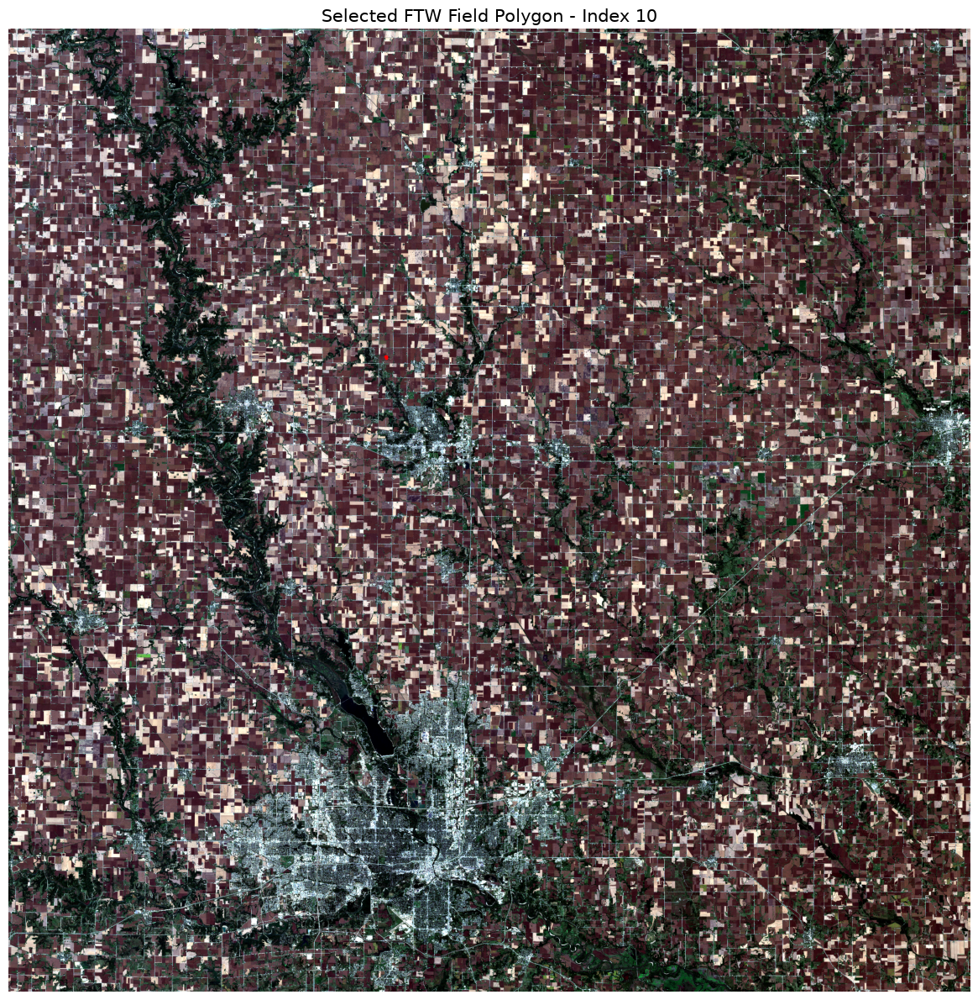

In [18]:
import matplotlib.pyplot as plt
from shapely.geometry import box

# Convert polygons to satellite image CRS
gdf_image = gdf.to_crs(image_crs)

# Create image boundary
image_box = box(
    image_bounds.left,
    image_bounds.bottom,
    image_bounds.right,
    image_bounds.top
)

# Select polygon by row index
selected_index = 10

selected_polygon = gdf_image.iloc[[selected_index]].copy()

# Check overlap with image
selected_polygon = selected_polygon[
    selected_polygon.intersects(image_box)
].copy()

if selected_polygon.empty:
    raise ValueError("Selected polygon does not overlap the satellite image.")

# Clip selected polygon to image boundary
selected_polygon.geometry = (
    selected_polygon.geometry.intersection(image_box)
)

# Plot
fig, ax = plt.subplots(figsize=(14, 12))

ax.imshow(
    rgb,
    extent=(
        image_bounds.left,
        image_bounds.right,
        image_bounds.bottom,
        image_bounds.top
    ),
    origin="upper"
)

selected_polygon.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2.5
)

ax.set_title(
    f"Selected FTW Field Polygon - Index {selected_index}",
    fontsize=15
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [19]:
display(gdf[["id", "geometry"]].head(20))

,id,geometry
0,1,"POLYGON ((445430 4663110, 445430 4663090, 4454..."
1,2,"POLYGON ((442960 4663110, 442960 4663100, 4429..."
2,3,"POLYGON ((445400 4663100, 445400 4663010, 4454..."
3,4,"POLYGON ((441580 4663100, 441580 4663020, 4415..."
4,5,"POLYGON ((441650 4662940, 441650 4662920, 4416..."
5,6,"POLYGON ((441740 4663110, 441740 4663100, 4417..."
6,7,"POLYGON ((441890 4663110, 441890 4663100, 4418..."
7,8,"POLYGON ((445550 4663110, 445550 4663100, 4455..."
8,9,"POLYGON ((444060 4663110, 444060 4663100, 4440..."
9,10,"POLYGON ((443540 4663110, 443540 4663060, 4435..."


In [21]:
selected_id = "1"

selected_polygon = gdf_image[
    gdf_image["id"] == selected_id
].copy()

In [22]:
selected_polygon

,metrics:area,id,metrics:perimeter,geometry
0,2500.0,1,240.0,"POLYGON ((445430 4663110, 445430 4663090, 4454..."


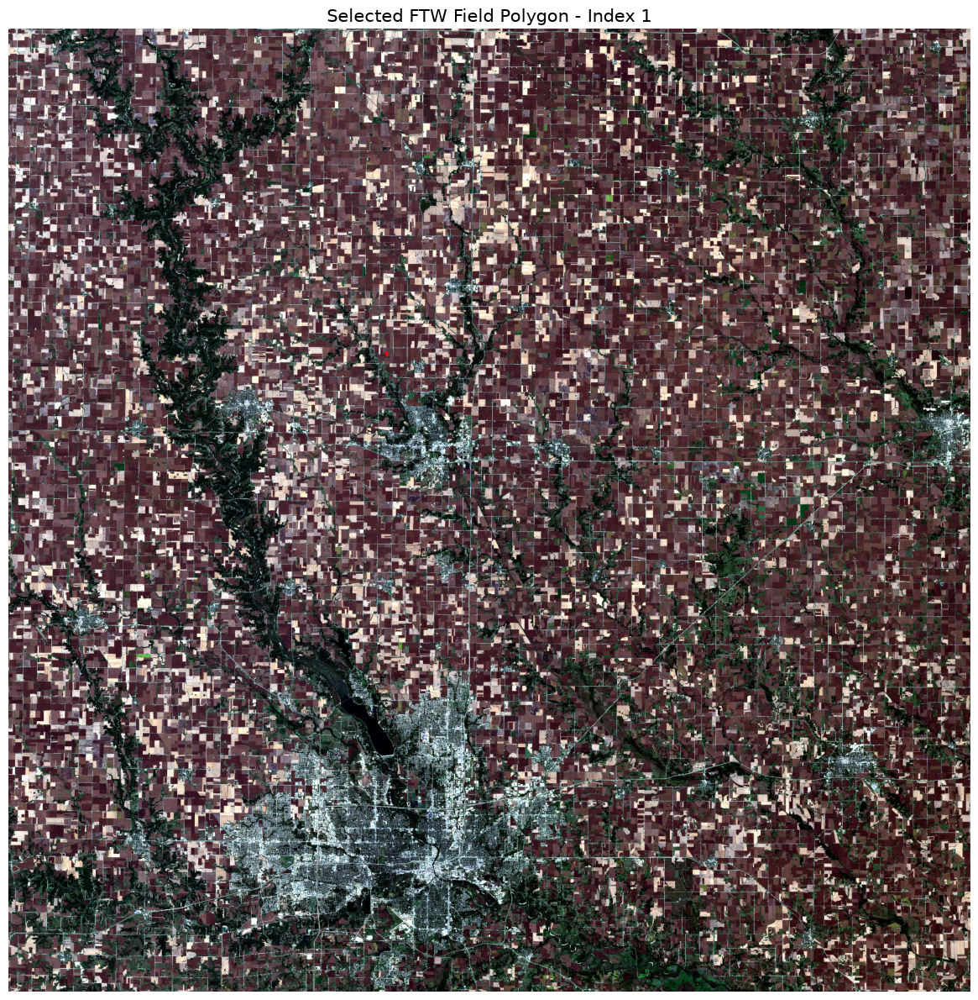

In [24]:
import matplotlib.pyplot as plt
from shapely.geometry import box

# Convert polygons to satellite image CRS
gdf_image = gdf.to_crs(image_crs)

# Create image boundary
image_box = box(
    image_bounds.left,
    image_bounds.bottom,
    image_bounds.right,
    image_bounds.top
)

# Select polygon by row index
selected_index = 1

selected_polygon = gdf_image.iloc[[selected_index]].copy()

# Check overlap with image
selected_polygon = selected_polygon[
    selected_polygon.intersects(image_box)
].copy()

if selected_polygon.empty:
    raise ValueError("Selected polygon does not overlap the satellite image.")

# Clip selected polygon to image boundary
selected_polygon.geometry = (
    selected_polygon.geometry.intersection(image_box)
)

# Plot
fig, ax = plt.subplots(figsize=(14, 12))

ax.imshow(
    rgb,
    extent=(
        image_bounds.left,
        image_bounds.right,
        image_bounds.bottom,
        image_bounds.top
    ),
    origin="upper"
)

selected_polygon.boundary.plot(
    ax=ax,
    color="red",
    linewidth=2.5
)

ax.set_title(
    f"Selected FTW Field Polygon - Index {selected_index}",
    fontsize=15
)

ax.set_axis_off()

plt.tight_layout()
plt.show()